Praktikum Week 9 Mata Kuliah Kecerdasan Buatan<br>
Materi: Neural Network (klasifikasi angka tulisan tangan dengan dataset MNIST)<br>
Kode Mata Kuliah: 4233201<br><br>
Nama: Tika Altiora Sitanggang<br>
NIM: 42324025<br>
Program Studi: D-III Teknologi Informasi<br>
Institut Teknologi Del

Tugas dari dosen: mengimplementasikan kode praktikum Neural Network dengan dataset yang berbeda, lalu menjelaskan apa yang dibuat.

Kode contoh dari dosen memakai dataset Fashion MNIST (gambar pakaian). Di tugas ini saya menggantinya dengan dataset MNIST, yaitu gambar angka tulisan tangan 0 sampai 9.

Alasan saya memilih MNIST: ukuran gambarnya sama dengan Fashion MNIST (28 x 28 piksel, hitam putih) dan jumlah kelasnya juga sama (10 kelas). Jadi struktur model dari contoh dosen bisa dipakai tanpa perubahan besar. Yang berubah hanya isi datanya. Kalau di contoh dosen model belajar mengenali jenis pakaian, di sini model belajar mengenali angka.

Isi dataset MNIST ada 60.000 gambar untuk training dan 10.000 gambar untuk testing. Setiap gambar adalah satu angka tulisan tangan beserta labelnya (0 sampai 9).

Alur yang saya kerjakan:
1. Install library
2. Load dataset dan melihat isinya
3. Normalisasi data
4. Membuat model Neural Network
5. Melatih model
6. Mengevaluasi model
7. Membuat prediksi dan menganalisis kesalahan model
8. Kesimpulan

Selain kode dari dosen, saya menambahkan beberapa bagian kecil (cek jumlah gambar tiap angka, confusion matrix, dan contoh gambar yang salah ditebak) supaya hasilnya lebih mudah dianalisis.

Langkah 1. Install library

Baris ini memasang library yang dipakai: tensorflow untuk membangun neural network, numpy untuk hitungan array, matplotlib untuk membuat gambar dan grafik, dan scikit-learn untuk confusion matrix. Kalau library sudah terpasang, pip hanya menampilkan tulisan "already satisfied" dan tidak mengunduh ulang.

In [ ]:
!pip install tensorflow numpy matplotlib scikit-learn

Langkah 2. Import library dan load dataset

Di sini saya mengimpor library, lalu memuat dataset MNIST dengan mnist.load_data(). Hasilnya terbagi menjadi dua pasang: data training (untuk belajar) dan data testing (untuk menguji model). Masing masing terdiri dari gambar dan label.

Baris tf.keras.utils.set_random_seed(42) saya tambahkan supaya angka acak di awal training dipatok. Dengan begitu hasilnya tidak berubah jauh kalau kode dijalankan ulang.

Perintah print di bagian bawah dipakai untuk mengecek bentuk data.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

# Supaya hasil training relatif sama setiap kali dijalankan
tf.keras.utils.set_random_seed(42)

# Load dataset MNIST (angka tulisan tangan 0 sampai 9)
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

print("Bentuk train_images :", train_images.shape)
print("Bentuk train_labels :", train_labels.shape)
print("Bentuk test_images  :", test_images.shape)
print("Bentuk test_labels  :", test_labels.shape)
print("Nilai piksel minimum dan maksimum:", train_images.min(), train_images.max())

Bentuk train_images : (60000, 28, 28)
Bentuk train_labels : (60000,)
Bentuk test_images  : (10000, 28, 28)
Bentuk test_labels  : (10000,)
Nilai piksel minimum dan maksimum: 0 255


Hasilnya: train_images berbentuk (60000, 28, 28), artinya ada 60.000 gambar berukuran 28 x 28 piksel. train_labels berbentuk (60000,), yaitu satu angka label untuk tiap gambar. Data testing berisi 10.000 gambar.

Nilai piksel berkisar dari 0 sampai 255 (0 hitam, 255 putih), jadi masih perlu dinormalisasi sebelum dipakai untuk training.

Sebelum membuat model, saya cek dulu apakah jumlah gambar untuk tiap angka seimbang. np.bincount menghitung berapa kali tiap label muncul di data training. Kalau ada angka yang jumlahnya jauh lebih sedikit dari yang lain, model bisa kurang bagus mengenali angka itu.

In [ ]:
# Cek jumlah gambar untuk setiap angka di data training
jumlah_per_kelas = np.bincount(train_labels)
for angka, jumlah in enumerate(jumlah_per_kelas):
    print(f"Angka {angka}: {jumlah} gambar")

Angka 0: 5923 gambar
Angka 1: 6742 gambar
Angka 2: 5958 gambar
Angka 3: 6131 gambar
Angka 4: 5842 gambar
Angka 5: 5421 gambar
Angka 6: 5918 gambar
Angka 7: 6265 gambar
Angka 8: 5851 gambar
Angka 9: 5949 gambar


Jumlah gambar tiap angka ada di rentang 5.421 (angka 5) sampai 6.742 (angka 1). Selisihnya tidak terlalu jauh, jadi data bisa dibilang cukup seimbang dan tidak perlu diatur ulang.

Bagian ini menampilkan 25 gambar pertama dari data training dalam kotak 5 x 5. plt.imshow dengan cmap='gray' menampilkan gambar dalam skala abu-abu, dan label aslinya saya tulis di bawah setiap gambar. Tujuannya hanya untuk melihat seperti apa isi datanya.

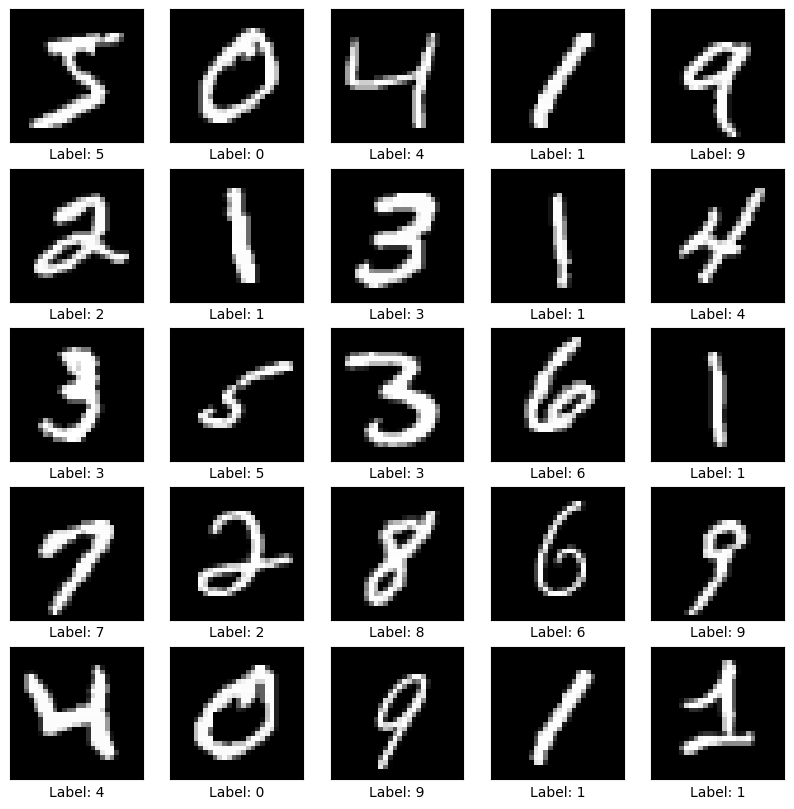

In [ ]:
# Melihat contoh gambar
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
    plt.xlabel(f"Label: {train_labels[i]}")
plt.show()

Terlihat tulisan tangan tiap orang berbeda. Ada yang rapi, ada yang miring, ada yang tipis atau tebal. Itu yang membuat tugas mengenali angka tidak sesederhana kelihatannya.

Langkah 3. Normalisasi data

Nilai piksel asli ada di rentang 0 sampai 255. Saya bagi dengan 255 supaya rentangnya menjadi 0 sampai 1. Normalisasi membuat proses training lebih stabil dan lebih cepat, karena angka input yang besar bisa membuat model sulit belajar. Yang dinormalisasi hanya gambarnya, label tidak diubah.

Hasil print di bawah menunjukkan nilai minimum 0.0 dan maksimum 1.0, jadi normalisasinya sudah berjalan.

In [ ]:
# Normalize nilai piksel gambar ke rentang [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

print("Nilai piksel minimum dan maksimum sekarang:", train_images.min(), train_images.max())

Nilai piksel minimum dan maksimum sekarang: 0.0 1.0


Langkah 4. Membuat model Neural Network

Model dibuat dengan Sequential, artinya layer disusun berurutan dari input sampai output. Isinya ada empat bagian:

1. Input(shape=(28, 28)) menentukan bentuk data masuk, yaitu gambar 28 x 28 piksel.
2. Flatten() meratakan gambar 28 x 28 menjadi satu baris panjang berisi 784 angka, karena layer Dense hanya menerima data satu dimensi.
3. Dense(128, activation='relu') adalah hidden layer dengan 128 neuron. Fungsi aktivasi ReLU mengubah nilai negatif menjadi 0 dan membiarkan nilai positif, sehingga model bisa mempelajari pola yang tidak lurus.
4. Dense(10, activation='softmax') adalah output layer dengan 10 neuron, satu untuk tiap angka 0 sampai 9. Softmax mengubah 10 keluaran itu menjadi probabilitas yang jumlahnya 1. Angka dengan probabilitas paling besar menjadi tebakan model.

Di contoh dosen, bentuk input ditulis di dalam Flatten (input_shape). Saya memakai Input(shape) karena di versi Keras yang baru cara lama itu memunculkan peringatan. Fungsinya sama saja.

model.summary() menampilkan ringkasan susunan layer dan jumlah parameternya.

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

# Membuat model Neural Network
model = Sequential([
    Input(shape=(28, 28)),            # Bentuk input: gambar 28x28 piksel
    Flatten(),                        # Mengubah gambar 28x28 menjadi vektor 1D dengan panjang 784
    Dense(128, activation='relu'),    # Hidden layer dengan 128 neuron
    Dense(10, activation='softmax')   # Output layer dengan 10 neuron untuk angka 0 sampai 9
])

# Melihat ringkasan arsitektur model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Penjelasan jumlah parameter:
1. Flatten: 0 parameter, karena hanya mengubah bentuk data.
2. Dense 128: 100.480 parameter, dari 784 x 128 bobot ditambah 128 bias.
3. Dense 10: 1.290 parameter, dari 128 x 10 bobot ditambah 10 bias.

Totalnya 101.770 parameter. Angkanya sama dengan model Fashion MNIST di contoh dosen karena susunan layernya memang sama. Yang beda hanya data yang dipelajari.

Langkah 5. Melatih model

Sebelum dilatih, model harus dikompilasi dulu dengan model.compile:
1. optimizer='adam' adalah cara model memperbarui bobotnya setiap kali belajar. Adam otomatis menyesuaikan besar langkah belajarnya.
2. loss='sparse_categorical_crossentropy' adalah ukuran seberapa salah tebakan model. Jenis ini dipakai karena label saya berupa angka bulat 0 sampai 9, bukan format one hot.
3. metrics=['accuracy'] membuat model melaporkan akurasi di setiap epoch.

Setelah itu model.fit melatih model. epochs=10 berarti seluruh data training dilewatkan ke model sebanyak 10 kali. validation_data dipakai untuk memantau performa model di data yang tidak dipakai belajar. Saya menambahkan verbose=2 supaya hasil tiap epoch tampil satu baris saja.

Catatan: seperti di contoh dosen, validation_data di sini memakai data testing. Idealnya data validasi dipisah dari data testing, tapi untuk praktikum ini saya ikuti contoh yang diberikan.

In [ ]:
# Kompilasi model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Melatih model dengan data training
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels), verbose=2)

Epoch 1/10


1875/1875 - 5s - 3ms/step - accuracy: 0.9276 - loss: 0.2530 - val_accuracy: 0.9588 - val_loss: 0.1345


Epoch 2/10


1875/1875 - 5s - 3ms/step - accuracy: 0.9670 - loss: 0.1112 - val_accuracy: 0.9699 - val_loss: 0.0983


Epoch 3/10


1875/1875 - 4s - 2ms/step - accuracy: 0.9775 - loss: 0.0754 - val_accuracy: 0.9726 - val_loss: 0.0868


... (10 outputs left out)

Epoch 9/10


1875/1875 - 4s - 2ms/step - accuracy: 0.9958 - loss: 0.0156 - val_accuracy: 0.9765 - val_loss: 0.0862


Epoch 10/10


1875/1875 - 5s - 3ms/step - accuracy: 0.9968 - loss: 0.0119 - val_accuracy: 0.9762 - val_loss: 0.0883


Dari hasil training terlihat akurasi training naik dari sekitar 92,8% di epoch 1 menjadi sekitar 99,7% di epoch 10. Akurasi validasi naik dari sekitar 95,9% menjadi sekitar 97,6%. Loss training terus turun, artinya tebakan model makin lama makin tepat.

Langkah 6. Evaluasi model

model.evaluate menguji model pada 10.000 gambar testing dan mengembalikan nilai loss dan akurasi. Verbose saya matikan supaya yang tampil hanya hasil akhirnya.

In [ ]:
# Evaluasi model dengan data pengujian
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)

print(f'\nTest loss     : {test_loss:.4f}')
print(f'Test accuracy : {test_acc:.4f}')


Test loss     : 0.0883
Test accuracy : 0.9762


Akurasi di data testing sekitar 0,9762 atau 97,62%. Artinya dari 10.000 gambar testing, sekitar 9.762 gambar ditebak dengan benar. Loss-nya sekitar 0,0883.

Fungsi plot_history menggambar dua grafik dari history hasil training. Grafik kiri membandingkan akurasi training dan akurasi validasi di setiap epoch. Grafik kanan membandingkan loss training dan loss validasi. Membandingkan keduanya berguna untuk melihat apakah model benar benar belajar atau hanya menghafal.

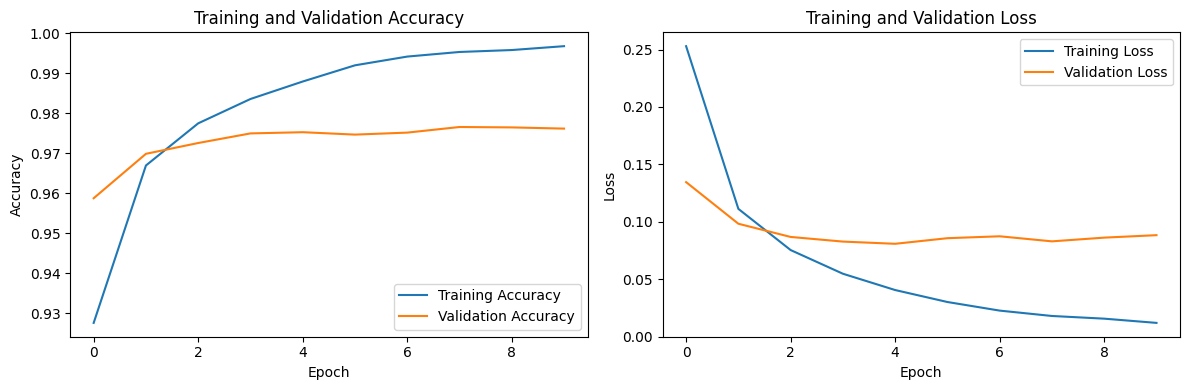

In [ ]:
# Mendefinisikan fungsi untuk memvisualisasikan akurasi dan loss
def plot_history(history):
    plt.figure(figsize=(12, 4))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

# Memanggil fungsi visualisasi
plot_history(history)

Cara membaca grafiknya:
1. Akurasi training terus naik sampai sekitar 99,7%, sedangkan akurasi validasi berhenti di sekitar 97,5% sampai 97,7% mulai epoch ke 4.
2. Loss training terus turun. Loss validasi paling rendah di epoch 5 (sekitar 0,081), lalu naik pelan pelan sampai sekitar 0,088 di epoch 10.

Ada selisih sekitar 2 poin persen antara akurasi training dan validasi. Ini tanda overfitting ringan, yaitu model sedikit lebih jago di data yang sudah pernah dilihat daripada di data baru. Tapi selisihnya masih kecil, jadi model ini masih bisa dibilang bagus.

Langkah 7. Prediksi

model.predict menghasilkan 10 probabilitas untuk setiap gambar testing. np.argmax mengambil angka dengan probabilitas paling besar sebagai tebakan model. Lalu 25 gambar testing pertama ditampilkan bersama tebakan dan angka aslinya.

Tulisan berwarna hijau berarti tebakannya benar, merah berarti salah. Pewarnaan ini saya tambahkan dari kode contoh supaya kesalahan langsung kelihatan.

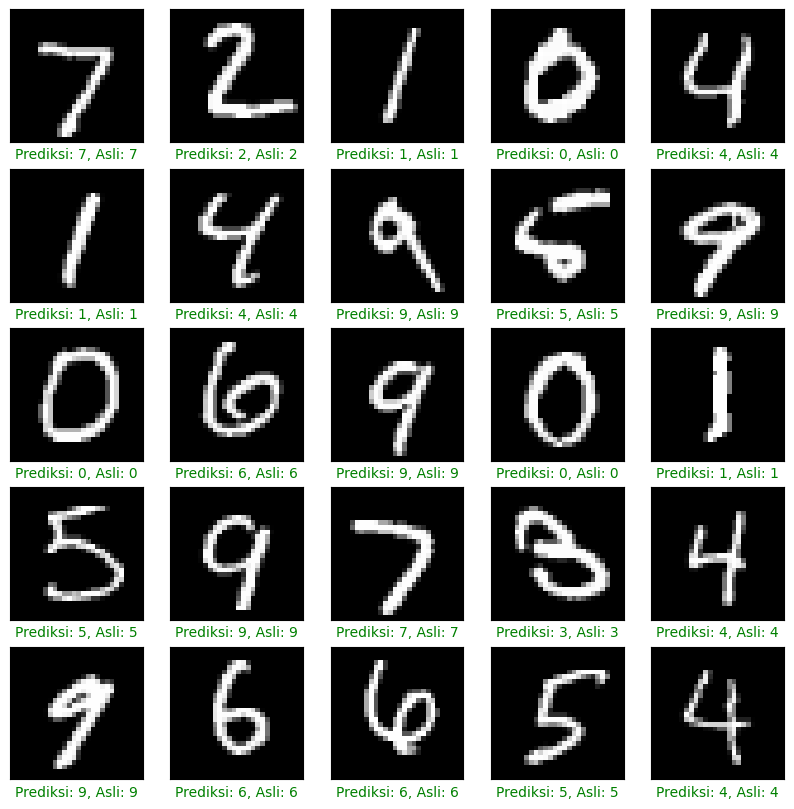

In [ ]:
# Melakukan prediksi pada gambar pengujian
predictions = model.predict(test_images, verbose=0)

# Contoh prediksi untuk 25 gambar pertama (hijau = benar, merah = salah)
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap='gray')
    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i]
    warna = 'green' if predicted_label == actual_label else 'red'
    plt.xlabel(f"Prediksi: {predicted_label}, Asli: {actual_label}", color=warna)
plt.show()

Dari 25 gambar pertama, semuanya ditebak dengan benar (tidak ada tulisan merah). Ini sejalan dengan akurasi yang tinggi tadi.

Akurasi saja belum menunjukkan angka mana yang sering tertukar, jadi saya tambahkan confusion matrix. Di tabel ini, baris adalah angka yang sebenarnya dan kolom adalah angka yang ditebak model. Kotak di diagonal adalah tebakan yang benar, kotak di luar diagonal adalah kesalahan.

classification_report menampilkan tiga ukuran untuk tiap angka:
1. precision: dari semua tebakan angka X, berapa yang memang benar angka X.
2. recall: dari semua gambar yang aslinya angka X, berapa yang berhasil ditebak.
3. f1-score: gabungan precision dan recall.

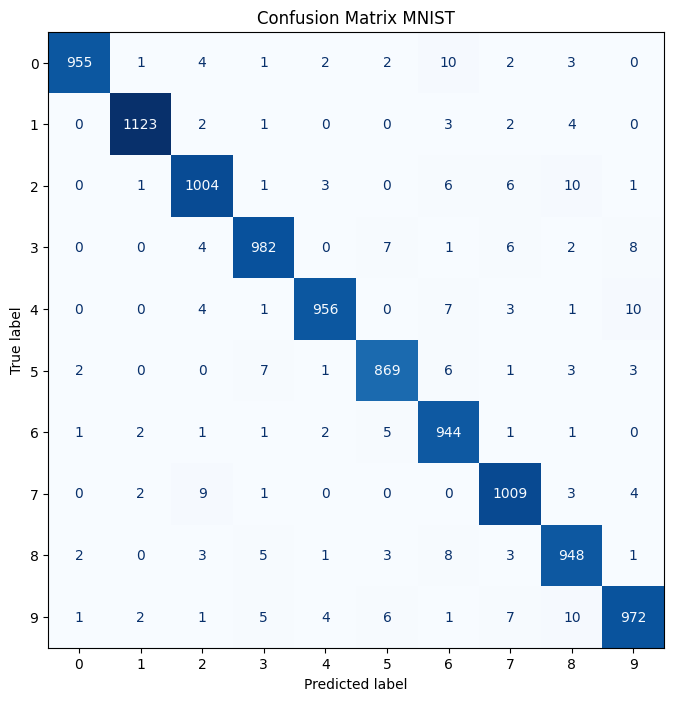

              precision    recall  f1-score   support

           0     0.9938    0.9745    0.9840       980
           1     0.9929    0.9894    0.9912      1135
           2     0.9729    0.9729    0.9729      1032
           3     0.9771    0.9723    0.9747      1010
           4     0.9866    0.9735    0.9800       982
           5     0.9742    0.9742    0.9742       892
           6     0.9574    0.9854    0.9712       958
           7     0.9702    0.9815    0.9758      1028
           8     0.9624    0.9733    0.9678       974
           9     0.9730    0.9633    0.9681      1009

    accuracy                         0.9762     10000
   macro avg     0.9760    0.9760    0.9760     10000
weighted avg     0.9763    0.9762    0.9762     10000



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Mengubah probabilitas menjadi angka tebakan (ambil yang paling besar)
y_pred = np.argmax(predictions, axis=1)

# Confusion matrix
cm = confusion_matrix(test_labels, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Confusion Matrix MNIST')
plt.show()

# Precision, recall, dan f1-score tiap angka
print(classification_report(test_labels, y_pred, digits=4))

Diagonal confusion matrix terlihat jauh lebih pekat dari kotak lain, artinya sebagian besar tebakan benar. Angka yang paling mudah dikenali adalah 1 (f1-score sekitar 0,991), mungkin karena bentuknya sederhana. Yang paling sulit adalah 8 dan 9 (f1-score sekitar 0,968).

Kesalahan yang paling sering terjadi ada di beberapa pasangan: angka 0 ditebak 6, angka 2 ditebak 8, angka 4 ditebak 9, dan angka 9 ditebak 8, masing masing sekitar 10 kali dari 10.000 gambar. Pasangan angka ini memang punya bentuk yang bisa mirip kalau ditulis tidak rapi.

Terakhir, saya ingin melihat langsung gambar apa saja yang salah ditebak. y_pred != test_labels memilih gambar yang tebakannya berbeda dengan label aslinya, lalu 15 contoh pertama ditampilkan.

Jumlah gambar yang salah ditebak: 238 dari 10000


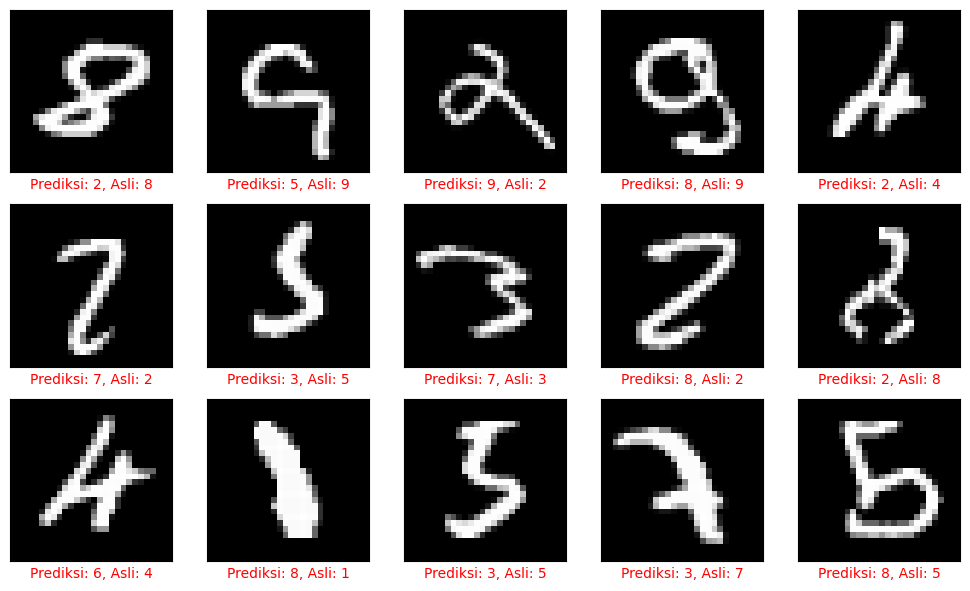

In [ ]:
# Mengambil gambar yang salah ditebak oleh model
index_salah = np.where(y_pred != test_labels)[0]
print(f"Jumlah gambar yang salah ditebak: {len(index_salah)} dari {len(test_labels)}")

# Menampilkan 15 contoh kesalahan pertama
plt.figure(figsize=(10, 6))
for n, i in enumerate(index_salah[:15]):
    plt.subplot(3, 5, n + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(test_images[i], cmap='gray')
    plt.xlabel(f"Prediksi: {y_pred[i]}, Asli: {test_labels[i]}", color='red')
plt.tight_layout()
plt.show()

Dari 10.000 gambar testing, ada 238 gambar yang salah ditebak (2,38%). Kalau dilihat langsung, banyak dari gambar ini memang tulisannya jelek atau tidak jelas, bahkan manusia pun bisa ragu membacanya. Jadi sebagian kesalahan model wajar terjadi.

Ringkasan hasil akhir dalam satu tampilan:

In [ ]:
# Ringkasan hasil akhir
print("Akurasi training terakhir  :", round(history.history['accuracy'][-1], 4))
print("Akurasi validasi terakhir  :", round(history.history['val_accuracy'][-1], 4))
print("Akurasi data uji           :", round(test_acc, 4))

Akurasi training terakhir  : 0.9968
Akurasi validasi terakhir  : 0.9762
Akurasi data uji           : 0.9762


Kesimpulan

Pada tugas ini saya menerapkan kode praktikum Neural Network dengan dataset MNIST (angka tulisan tangan) sebagai pengganti Fashion MNIST. Model yang dipakai sama dengan contoh dosen: Flatten, Dense 128 neuron dengan ReLU, dan Dense 10 neuron dengan Softmax, dilatih dengan Adam selama 10 epoch.

Hasilnya, akurasi di data testing mencapai sekitar 97,6%, dengan 238 gambar salah tebak dari 10.000 gambar. Sebagai pembanding, di contoh dosen dengan Fashion MNIST akurasi testingnya sekitar 88,3%. Akurasi di MNIST lebih tinggi kemungkinan karena bentuk angka lebih mudah dibedakan dibanding pakaian yang mirip satu sama lain, misalnya kaos dan kemeja.

Hal lain yang saya temukan:
1. Data tiap angka cukup seimbang, jadi tidak ada angka yang terlalu diuntungkan.
2. Ada overfitting ringan. Akurasi training sekitar 99,7% sedangkan akurasi validasi sekitar 97,6%.
3. Kesalahan paling banyak terjadi pada angka yang bentuknya mirip, seperti 4 dengan 9 dan 2 dengan 8.

Kalau ingin ditingkatkan, beberapa hal yang bisa dicoba adalah menambah layer Dropout untuk mengurangi overfitting, memakai early stopping supaya training berhenti di epoch terbaik, atau memakai Convolutional Neural Network (CNN) yang lebih cocok untuk data gambar.